In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# --------------------------------------------------------
# 1. PARÁMETROS DEL PROBLEMA
# --------------------------------------------------------
Lx, Ly = 3.0, 1.0       # dimensiones del dominio
nx, ny = 15, 5          # número de divisiones en x y en y (ajusta para más malla)
E = 210e9               # Young (Pa)
nu = 0.3                # Poisson
t = 0.01                # espesor (m)
traction = 1e6          # tracción horizontal en el borde derecho (Pa = N/m^2)

In [18]:
# --------------------------------------------------------
# 2. GENERAR MALLA TRIANGULAR REGULAR
#    (2 triángulos por rectángulo)
# --------------------------------------------------------
def generate_mesh(Lx, Ly, nx, ny):
    xs = np.linspace(0, Lx, nx+1)
    ys = np.linspace(0, Ly, ny+1)
    nodes = []
    for j in range(ny+1):
        for i in range(nx+1):
            nodes.append([xs[i], ys[j]])
    nodes = np.array(nodes)

    elems = []
    for j in range(ny):
        for i in range(nx):
            n1 = j*(nx+1) + i
            n2 = n1 + 1
            n3 = n1 + (nx+1)
            n4 = n3 + 1
            # triángulo 1
            elems.append([n1, n2, n4])
            # triángulo 2
            elems.append([n1, n4, n3])
    elems = np.array(elems, dtype=int)
    return nodes, elems

nodes, elems = generate_mesh(Lx, Ly, nx, ny)
nn = nodes.shape[0]
ne = elems.shape[0]

# --------------------------------------------------------
# 3. MATRIZ CONSTITUTIVA PLANO-ESFUERZO (plane stress)
# --------------------------------------------------------
D = (E / (1 - nu**2)) * np.array([
    [1,    nu,         0],
    [nu,   1,          0],
    [0,    0,  (1-nu)/2]
])

# --------------------------------------------------------
# 4. ENSAMBLA MATRIZ DE RIGIDEZ GLOBAL
#    CST: Ke = t*A * (B^T D B)
# --------------------------------------------------------
K = np.zeros((2*nn, 2*nn))

for el in range(ne):
    # nodos del elemento
    n = elems[el, :]
    x1, y1 = nodes[n[0], :]
    x2, y2 = nodes[n[1], :]
    x3, y3 = nodes[n[2], :]

    # área del triángulo
    Ae = 0.5 * np.linalg.det(np.array([
        [1, x1, y1],
        [1, x2, y2],
        [1, x3, y3]
    ]))

    # coeficientes bi, ci (ver PDF)
    b1 = y2 - y3
    b2 = y3 - y1
    b3 = y1 - y2
    c1 = x3 - x2
    c2 = x1 - x3
    c3 = x2 - x1

    B = (1 / (2*Ae)) * np.array([
        [b1,   0, b2,   0, b3,   0],
        [0,   c1, 0,   c2, 0,   c3],
        [c1,  b1, c2,  b2, c3,  b3]
    ])

    Ke = t * Ae * (B.T @ D @ B)

    # ensamblar
    dofs = []
    for ni in n:
        dofs.extend([2*ni, 2*ni+1])
    dofs = np.array(dofs, dtype=int)

    for i in range(6):
        for j in range(6):
            K[dofs[i], dofs[j]] += Ke[i, j]

# --------------------------------------------------------
# 5. VECTOR DE CARGA POR TRACCIÓN EN BORDE DERECHO
#    tracción horizontal = sigma_x * t * largo_borde
#    se reparte a los nodos de cada segmento
# --------------------------------------------------------
F = np.zeros(2*nn)

# nodos del borde derecho (x = Lx)
tol = 1e-9
right_nodes = [i for i, (x, y) in enumerate(nodes) if abs(x - Lx) < tol]

# ordenar por y para formar segmentos
right_nodes = sorted(right_nodes, key=lambda i: nodes[i,1])

for i in range(len(right_nodes)-1):
    nA = right_nodes[i]
    nB = right_nodes[i+1]
    yA = nodes[nA,1]
    yB = nodes[nB,1]
    length = np.sqrt( (Lx-Lx)**2 + (yB - yA)**2 )   # solo vertical
    # tracción * área_proyectada -> fuerza total en el tramo
    Ft = traction * t * length
    # se reparte mitad-mitad a los 2 nodos, en dirección +x
    F[2*nA] += Ft/2
    F[2*nB] += Ft/2

# --------------------------------------------------------
# 6. CONDICIONES DE BORDE DE DESPLAZAMIENTO (x=0)
# --------------------------------------------------------
left_nodes = [i for i, (x, y) in enumerate(nodes) if abs(x - 0.0) < tol]
fixed_dofs = []
for n in left_nodes:
    fixed_dofs.extend([2*n, 2*n+1])   # ux = uy = 0

all_dofs = np.arange(2*nn)
free_dofs = np.setdiff1d(all_dofs, fixed_dofs)

# reducir sistema
Kff = K[np.ix_(free_dofs, free_dofs)]
Ff = F[free_dofs]

# --------------------------------------------------------
# 7. RESOLVER
# --------------------------------------------------------
uf = np.linalg.solve(Kff, Ff)

U = np.zeros(2*nn)
U[free_dofs] = uf

Ux = U[0::2]
Uy = U[1::2]
Umag = np.sqrt(Ux**2 + Uy**2)


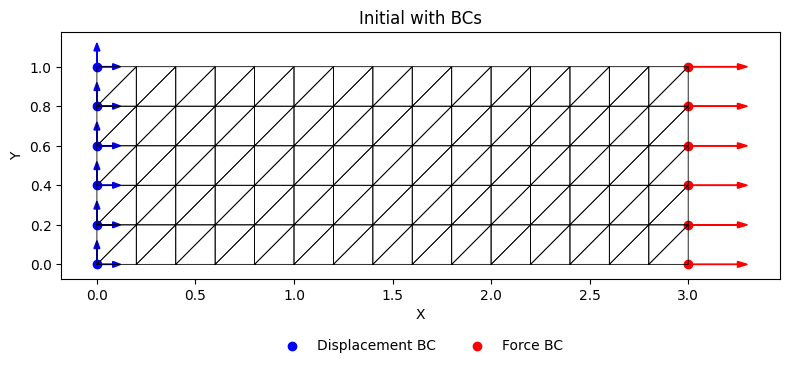

In [ ]:
# --------------------------------------------------------
# 8. PLOTS
# --------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(8,4)) 

# (a) malla + BCs
for el in elems:
    xy = nodes[el, :]
    poly = np.vstack((xy, xy[0]))  # cerrar
    ax1.plot(poly[:,0], poly[:,1], 'k-', linewidth=0.6)

# nodos con desplazamiento prescrito (azules)
ax1.scatter(nodes[left_nodes,0], nodes[left_nodes,1], c='b', label='Displacement BC')
for n in left_nodes:
    ax1.arrow(nodes[n,0], nodes[n,1],
              0.0, 0.08, head_width=0.03, head_length=0.04, fc='b', ec='b')
    ax1.arrow(nodes[n,0], nodes[n,1], 
              0.08, 0.0, head_width=0.03, head_length=0.04, fc='b', ec='b')

# nodos con carga (rojos, derecha)
ax1.scatter(nodes[right_nodes,0], nodes[right_nodes,1], c='r', label='Force BC')
for n in right_nodes:
    ax1.arrow(nodes[n,0], nodes[n,1],
              0.25, 0.0, head_width=0.03, head_length=0.05, fc='r', ec='r')

ax1.set_title('Initial with BCs')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')

ax1.legend(loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.35),frameon=False )
plt.tight_layout()
plt.show()

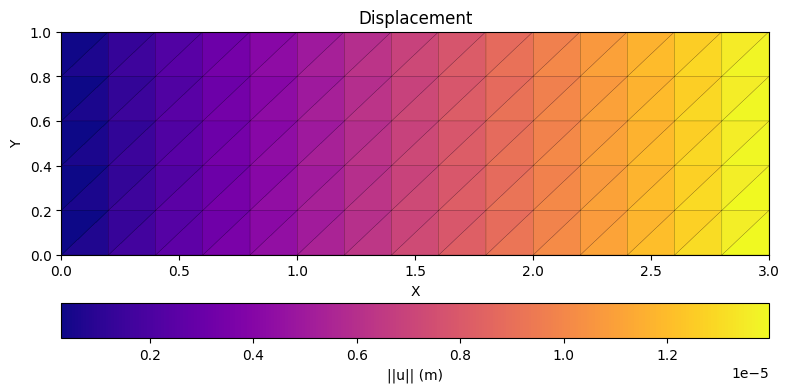

In [ ]:
fig, ax2 = plt.subplots(figsize=(8,4)) 
# desplazamiento

triangles = elems
tpc = ax2.tripcolor(nodes[:,0], nodes[:,1], triangles, Umag,
                    shading='flat', cmap='plasma')
for el in elems:
    xy = nodes[el, :]
    poly = np.vstack((xy, xy[0]))
    ax2.plot(poly[:,0], poly[:,1], 'k-', linewidth=0.2, alpha=0.4)

ax2.set_title('Displacement')
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_xlim(0, Lx)
ax2.set_ylim(0, Ly)

cbar = fig.colorbar(tpc, ax=ax2, orientation='horizontal', pad=0.15)
cbar.set_label('||u|| (m)')



plt.tight_layout()
plt.show()
